# PedagogyEval AI: experiments
**Fine-Grained Concept Graph Mapping and Explainable Partial-Credit Grading for Short Answers**

Runs on Google Colab or locally. Every number shown in the report is computed here and written to `results/` first;
the Streamlit *Results* page only reads these CSVs. Seed = 42 everywhere.

| § | Section |
|---|---|
| 0 | Setup + environment |
| 1 | Pilot evaluation (A/B/C): MAE, RMSE, exact match + sample outputs |
| 2 | SciEntsBank: accuracy, macro-F1, weighted-F1, confusion matrices per split |
| 3 | Ablations: no semantic / uniform weights / no negation check |
| 4 | Worst 10 errors per model |
| 5 | Plots (from the saved CSVs, app palette + mono font) |
| 6 | Metrics summary for the report |

## 0 · Setup
**On Colab**, either upload `pedagogyeval-ai.zip` (the project folder zipped) to `/content`, or set `REPO_URL` to a git
repository containing the project. Locally, run the notebook from the project's `notebooks/` folder.

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path

REPO_URL = ""  # optional: git URL of the project, used on Colab if no zip is uploaded
IN_COLAB = "google.colab" in sys.modules

def find_root():
    for cand in [Path.cwd(), Path.cwd().parent, Path("/content/pedagogyeval-ai")]:
        if (cand / "pedagogyeval" / "__init__.py").exists():
            return cand.resolve()
    return None

ROOT = find_root()
if ROOT is None and IN_COLAB:
    z = Path("/content/pedagogyeval-ai.zip")
    if z.exists():
        zipfile.ZipFile(z).extractall("/content")
    elif REPO_URL:
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/pedagogyeval-ai"], check=True)
    ROOT = find_root()
if ROOT is None:
    raise SystemExit("Project not found. On Colab upload pedagogyeval-ai.zip to /content or set REPO_URL; "
                     "locally, start Jupyter inside pedagogyeval-ai/notebooks.")
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "datasets", "networkx", "scikit-learn"], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "app"))
RESULTS = ROOT / "results"; FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT, "| colab:", IN_COLAB)

project root: /Users/mayank/Documents/NLPN/pedagogyeval-ai | colab: False


In [2]:
import json, platform, random, time
import numpy as np, pandas as pd, torch, sklearn, sentence_transformers, datasets as hf_datasets
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

import pedagogyeval
from pedagogyeval import Embedder
from pedagogyeval.data import load_pilot, load_pilot_rubrics, load_scientsbank
from pedagogyeval import experiments as X

t0 = time.time()
embedder = Embedder()  # models_cache/all-MiniLM-L6-v2, falls back to the Hub only if missing
env = {
    "python": platform.python_version(), "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__, "sklearn": sklearn.__version__,
    "sentence_transformers": sentence_transformers.__version__, "datasets": hf_datasets.__version__,
    "pedagogyeval": pedagogyeval.__version__, "cuda": torch.cuda.is_available(), "seed": SEED,
    "embedding_model_source": embedder.source, "model_load_seconds": round(time.time() - t0, 2),
}
(RESULTS / "environment.json").write_text(json.dumps(env, indent=2))
X.config_table().to_csv(RESULTS / "grader_configs.csv", index=False)
env

/Users/mayank/Documents/NLPN/pedagogyeval-ai/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1025 20:06:37.427000 53122 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5886.46it/s]

{'python': '3.11.9',
 'platform': 'macOS-26.6.2-arm64-arm-64bit',
 'numpy': '2.2.6',
 'pandas': '3.1.0',
 'torch': '2.14.1',
 'sklearn': '1.9.1',
 'sentence_transformers': '6.2.0',
 'datasets': '5.1.0',
 'pedagogyeval': '1.0.0',
 'cuda': False,
 'seed': 42,
 'embedding_model_source': '/Users/mayank/Documents/NLPN/pedagogyeval-ai/models_cache/all-MiniLM-L6-v2',
 'model_load_seconds': 0.27}

## 1 · Pilot evaluation
24 **authored** responses (6 questions × full / partial / wrong-but-topical / paraphrase). Gold marks were assigned by
the authors from the rubric. Model B's isotonic calibration is fitted **leave-one-question-out**, so it never sees the
question it grades; Model A's TF-IDF is fitted on reference answers only.

In [3]:
rubrics = load_pilot_rubrics(); pilot = load_pilot()
assert len(pilot) == 24 and pilot.groupby("question_id").size().eq(4).all()
pilot_preds, pilot_metrics, pilot_by_type = X.run_pilot(embedder, rubrics, pilot)
pilot_preds.to_csv(RESULTS / "pilot_predictions.csv", index=False)
pilot_metrics.to_csv(RESULTS / "pilot_metrics.csv", index=False)
pilot_by_type.to_csv(RESULTS / "pilot_by_type.csv", index=False)
sample = X.pilot_sample_table(pilot_preds)
sample.to_csv(RESULTS / "pilot_sample_outputs.csv", index=False)
pilot_metrics[pilot_metrics.model.isin(["A_tfidf", "B_embedding", "C_concept"])].round(3)

,model,label,n,mae,rmse,exact_match,norm_mae,review_rate
0,A_tfidf,A · TF-IDF,24,1.125,1.339,0.208,0.354,NaN
1,B_embedding,B · MiniLM,24,1.107,1.294,0.250,0.348,NaN
2,C_concept,C · Concept graph,24,0.500,0.946,0.708,0.156,0.208


In [4]:
sample[["response_id", "response", "gold", "A", "B", "C", "review", "missing"]].round(2)

,response_id,response,gold,A,B,C,review,missing
0,Q1_full,Plants use sunlight and carbon dioxide to make glucose and oxygen.,4.0,2.0,2.04,4.0,False,
1,Q1_para,"Leaves capture the sun's energy and absorb CO2 from the air, turning it into...",4.0,2.0,2.04,3.0,False,oxygen released
2,Q1_partial,Photosynthesis is how plants make their own food using light.,2.0,1.0,2.04,2.0,False,carbon dioxide intake; oxygen released
3,Q1_wrong,Plants breathe in oxygen and release carbon dioxide.,0.0,1.0,2.04,2.0,True,light energy
4,Q2_full,Osmosis is the movement of water molecules across a partially permeable memb...,3.0,3.0,3.00,3.0,False,
5,Q2_para,"The solvent passes through a selectively permeable barrier, travelling from ...",3.0,1.0,1.61,2.0,True,
6,Q2_partial,Osmosis is when water moves through a membrane.,2.0,1.0,2.22,2.0,False,dilute to concentrated
7,Q2_wrong,Osmosis is when salt particles spread out evenly through the air.,0.0,1.0,1.61,0.0,False,movement of water; partially permeable membrane; dilute to concentrated
8,Q3_full,A primary key is a column that uniquely identifies each row in a table; it c...,3.0,2.0,3.00,3.0,False,
9,Q3_para,It is a field whose value is different for every record and must always be f...,3.0,1.0,1.61,1.0,True,cannot be null


## 2 · SciEntsBank (SemEval-2013 Task 7)
The loader **first prints splits, columns, labels and class balance**, and resolves column names instead of assuming them.
Official test splits are kept (unseen-answers / unseen-questions / unseen-domains); dev (15 %, stratified, seed 42) is carved
from train. One decision threshold per model and task is tuned on dev for macro-F1 and then frozen.

> **Approximation:** SciEntsBank has no concept rubrics. Model C's concepts are auto-derived from each reference
> answer (clauses + stopword-delimited chunks, weights ∝ content words). Treat C's numbers here as a lower bound on what
> an expert rubric would give.

In [5]:
frames = load_scientsbank(verbose=True)
balance = []
for split, df in frames.items():
    for task in ("2way", "3way"):
        vc = df[f"label_{task}"].value_counts()
        for lab, n in vc.items():
            balance.append({"split": split, "task": task, "label": lab, "n": int(n), "share": round(n / vc.sum(), 4)})
balance = pd.DataFrame(balance); balance.to_csv(RESULTS / "scientsbank_class_balance.csv", index=False)
balance.pivot_table(index=["task", "label"], columns="split", values="n", sort=False)

Dataset: Atomi/sem_eval_2013_task_7
  split 'train': 47866 rows
  split 'test': 23656 rows
  columns: ['split', 'classification_type', 'corpus', 'test_set', 'question_qtype', 'question_id', 'question_module', 'question_stype', 'question', 'reference_answer_quality', 'reference_answer_id', 'reference_answer_file_id', 'reference_answer', 'student_answer_count', 'student_answer_match', 'student_answer_id', 'student_answer_label', 'student_answer', 'label_5way']
  resolved: {'corpus': 'corpus', 'task': 'classification_type', 'test_set': 'test_set', 'question_id': 'question_id', 'question': 'question', 'reference_answer': 'reference_answer', 'answer_id': 'student_answer_id', 'student_answer': 'student_answer', 'label': 'student_answer_label'}

  [train] rows by corpus x task x test_set:
corpus       classification_type  test_set
    beetle       2way                 training    18361
                 3way                 training    19351
    sciEntsBank  2way                 training     5


  SciEntsBank evaluation frames (unique answers):
    train             n= 4223  3-way: incorrect=2092, correct=1707, contradictory=424
    dev               n=  746  3-way: incorrect=370, correct=301, contradictory=75
    unseen-answers    n=  540  3-way: incorrect=249, correct=233, contradictory=58
    unseen-domains    n= 4562  3-way: incorrect=2228, correct=1917, contradictory=417
    unseen-questions  n=  733  3-way: incorrect=368, correct=301, contradictory=64


split                train    dev  unseen-answers  unseen-domains  unseen-questions
task label                                                                         
2way incorrect      2516.0  445.0           307.0          2645.0             432.0
     correct        1707.0  301.0           233.0          1917.0             301.0
3way incorrect      2092.0  370.0           249.0          2228.0             368.0
     correct        1707.0  301.0           233.0          1917.0             301.0
     contradictory   424.0   75.0            58.0           417.0              64.0

In [6]:
from pedagogyeval.data import derive_rubric
ex = frames["dev"].iloc[0]
r = derive_rubric(ex.question_id, ex.question, ex.reference_answer)
print("REFERENCE:", ex.reference_answer)
for c in r.concepts: print(f"  {c.id} w={c.weight:.2f}  {c.description!r}  synonyms={c.synonyms}")

REFERENCE: A solution is a mixture formed when a solid dissolves in a liquid.
  c1 w=1.00  'A solution is a mixture formed'  synonyms=['mixture formed']
  c2 w=1.00  'a solid dissolves in a liquid'  synonyms=['solid dissolves', 'liquid']


In [7]:
t0 = time.time()
sb_scores = X.score_scientsbank(frames, embedder)
print(f"scored {sb_scores.answer_id.nunique()} answers x {sb_scores.model.nunique()} models in {time.time() - t0:.0f}s")
sb_metrics, sb_conf, sb_preds = X.evaluate_scientsbank(sb_scores)
sb_scores.drop(columns=["student_answer", "reference_answer"]).to_csv(RESULTS / "scientsbank_scores.csv", index=False)
sb_metrics.to_csv(RESULTS / "scientsbank_metrics.csv", index=False)
sb_conf.to_csv(RESULTS / "scientsbank_confusion.csv", index=False)
sb_preds.to_csv(RESULTS / "scientsbank_predictions.csv", index=False)
main = sb_metrics[sb_metrics.model.isin(["A_tfidf", "B_embedding", "C_concept"])]
main.pivot_table(index=["task", "model"], columns="split", values="macro_f1", sort=False).round(3)

  scoring dev (n=746)


  scoring unseen-answers (n=540)


  scoring unseen-domains (n=4562)


  scoring unseen-questions (n=733)


scored 6581 answers x 6 models in 29s


split               dev  unseen-answers  unseen-domains  unseen-questions
task model                                                               
2way A_tfidf      0.598           0.609           0.616             0.603
     B_embedding  0.638           0.650           0.630             0.639
     C_concept    0.663           0.654           0.650             0.600
3way A_tfidf      0.381           0.387           0.404             0.397
     B_embedding  0.408           0.417           0.410             0.419
     C_concept    0.435           0.423           0.417             0.400

In [8]:
main[["task", "split", "model", "accuracy", "macro_f1", "weighted_f1", "threshold", "n"]].round(3)

,task,split,model,accuracy,macro_f1,weighted_f1,threshold,n
0,2way,dev,A_tfidf,0.598,0.598,0.600,0.08,746
1,2way,unseen-answers,A_tfidf,0.609,0.609,0.608,0.08,540
2,2way,unseen-domains,A_tfidf,0.618,0.616,0.613,0.08,4562
3,2way,unseen-questions,A_tfidf,0.608,0.603,0.595,0.08,733
4,2way,dev,B_embedding,0.642,0.638,0.645,0.51,746
5,2way,unseen-answers,B_embedding,0.650,0.650,0.651,0.51,540
6,2way,unseen-domains,B_embedding,0.631,0.630,0.628,0.51,4562
7,2way,unseen-questions,B_embedding,0.640,0.639,0.636,0.51,733
8,2way,dev,C_concept,0.676,0.663,0.676,0.46,746
9,2way,unseen-answers,C_concept,0.659,0.654,0.660,0.46,540


In [9]:
for task in ("2way", "3way"):
    for split in ["unseen-answers", "unseen-questions", "unseen-domains"]:
        print(f"\n== {task} · {split}")
        for m in ["A_tfidf", "B_embedding", "C_concept"]:
            cm = sb_conf[(sb_conf.task == task) & (sb_conf.split == split) & (sb_conf.model == m)]
            print(m); print(cm.pivot(index="gold", columns="pred", values="count").to_string())


== 2way · unseen-answers
A_tfidf
pred       correct  incorrect
gold                         
correct        168         65
incorrect      146        161
B_embedding
pred       correct  incorrect
gold                         
correct        166         67
incorrect      122        185
C_concept
pred       correct  incorrect
gold                         
correct        145         88
incorrect       96        211

== 2way · unseen-questions
A_tfidf
pred       correct  incorrect
gold                         
correct        265         36
incorrect      251        181
B_embedding
pred       correct  incorrect
gold                         
correct        253         48
incorrect      216        216
C_concept
pred       correct  incorrect
gold                         
correct        188        113
incorrect      178        254

== 2way · unseen-domains
A_tfidf
pred       correct  incorrect
gold                         
correct       1542        375
incorrect     1369       1276
B_embedding


## 3 · Ablations (Model C)
* **no semantic**: lexical synonyms only · **uniform weights**: every concept weight = M / n · **no negation check**.

On the pilot, concept weights are equal by design, so *uniform weights* must equal the full model there. The
*negation* ablation can only change a pilot mark if the negation flag fires; the cell below reports how many pilot
responses contain a negation word and on how many the flag actually fired. SciEntsBank (content-weighted auto rubrics,
natural negations) is where these two ablations can differ.

In [10]:
abl = ["C_concept", "C_no_semantic", "C_uniform_weights", "C_no_negation"]
ap = pilot_metrics[pilot_metrics.model.isin(abl)].copy()
full = ap.set_index("model").loc["C_concept"]
ap["delta_mae_vs_full"] = ap.mae - full.mae
ap["delta_exact_vs_full"] = ap.exact_match - full.exact_match
n_neg = int(pilot.response.str.contains(r"\b(?:not|never|no|without|cannot)\b|n't", case=False, regex=True).sum())
equal_w = all(len({c.weight for c in r.concepts}) == 1 for r in rubrics.values())
ap["note"] = None
ap.loc[ap.model == "C_uniform_weights", "note"] = f"pilot rubrics use equal weights: {equal_w}"
n_fired = int(pilot_preds[pilot_preds.model == "C_concept"].review_reason.fillna("").str.contains("negation").sum())
ap.loc[ap.model == "C_no_negation", "note"] = f"pilot responses with a negation word: {n_neg}; negation flag fired on: {n_fired}"
ap.to_csv(RESULTS / "ablations_pilot.csv", index=False)

sb_abl = sb_metrics[sb_metrics.model.isin(abl)]
test = sb_abl[sb_abl.split != "dev"]
asb = test.groupby(["model", "label", "task"], sort=False).agg(macro_f1_test_mean=("macro_f1", "mean"), accuracy_test_mean=("accuracy", "mean")).reset_index()
per_split = test.pivot_table(index=["model", "task"], columns="split", values="macro_f1").add_prefix("macro_f1_").reset_index()
asb = asb.merge(per_split, on=["model", "task"])
asb.to_csv(RESULTS / "ablations_scientsbank.csv", index=False)
display(ap[["model", "mae", "rmse", "exact_match", "delta_mae_vs_full", "note"]].round(3))
asb.round(3)

,model,mae,rmse,exact_match,delta_mae_vs_full,note
2,C_concept,0.500,0.946,0.708,0.000,None
3,C_no_semantic,0.542,1.099,0.708,0.042,None
4,C_uniform_weights,0.500,0.946,0.708,0.000,pilot rubrics use equal weights: True
5,C_no_negation,0.500,0.946,0.708,0.000,pilot responses with a negation word: 2; negation flag fired on: 0


,model,label,task,macro_f1_test_mean,accuracy_test_mean,macro_f1_unseen-answers,macro_f1_unseen-domains,macro_f1_unseen-questions
0,C_concept,C · Concept graph,2way,0.635,0.638,0.654,0.650,0.600
1,C_no_semantic,C − semantic,2way,0.612,0.646,0.604,0.617,0.615
2,C_uniform_weights,C − weights (uniform),2way,0.645,0.647,0.647,0.647,0.640
3,C_no_negation,C − negation check,2way,0.636,0.639,0.653,0.650,0.606
4,C_concept,C · Concept graph,3way,0.413,0.576,0.423,0.417,0.400
5,C_no_semantic,C − semantic,3way,0.388,0.567,0.383,0.391,0.388
6,C_uniform_weights,C − weights (uniform),3way,0.412,0.574,0.412,0.417,0.407
7,C_no_negation,C − negation check,3way,0.405,0.579,0.412,0.410,0.393


## 4 · Worst 10 errors per model

In [11]:
wp = X.worst_errors_pilot(pilot_preds, 10); wp.to_csv(RESULTS / "worst_errors_pilot.csv", index=False)
wp.round(2)

,model,response_id,response_type,response,gold,pred,max_marks,abs_error,review_reason,missing
0,A_tfidf,Q1_full,full,Plants use sunlight and carbon dioxide to make glucose and oxygen.,4.0,2.00,4.0,2.00,NaN,NaN
18,A_tfidf,Q1_para,paraphrase,"Leaves capture the sun's energy and absorb CO2 from the air, turning it into...",4.0,2.00,4.0,2.00,NaN,NaN
42,A_tfidf,Q2_para,paraphrase,"The solvent passes through a selectively permeable barrier, travelling from ...",3.0,1.00,3.0,2.00,NaN,NaN
66,A_tfidf,Q3_para,paraphrase,It is a field whose value is different for every record and must always be f...,3.0,1.00,3.0,2.00,NaN,NaN
90,A_tfidf,Q4_para,paraphrase,A model with far more capacity than the data warrants learns its training ex...,3.0,1.00,3.0,2.00,NaN,NaN
96,A_tfidf,Q5_full,full,DNS translates a website's name to an IP address.,3.0,1.00,3.0,2.00,NaN,NaN
114,A_tfidf,Q5_para,paraphrase,"When you type example.com, a directory service looks up the numeric location...",3.0,1.00,3.0,2.00,NaN,NaN
138,A_tfidf,Q6_para,paraphrase,Criminals message you while posing as your bank so that you hand over your l...,3.0,1.00,3.0,2.00,NaN,NaN
6,A_tfidf,Q1_partial,partial,Photosynthesis is how plants make their own food using light.,2.0,1.00,4.0,1.00,NaN,NaN
12,A_tfidf,Q1_wrong,wrong_topical,Plants breathe in oxygen and release carbon dioxide.,0.0,1.00,4.0,1.00,NaN,NaN


In [12]:
ws = X.worst_errors_scientsbank(sb_preds, sb_scores, 10); ws.to_csv(RESULTS / "worst_errors_scientsbank.csv", index=False)
ws.round(3)

,model,split,answer_id,question_id,reference_answer,student_answer,gold,pred,score,negated,confidence_gap
40251,A_tfidf,unseen-answers,EM.27b.638.1,EM_27b,Many tiny bubbles will rise from the calcite when the calcite contacts the c...,It would fizzles.,correct,incorrect,0.000,False,1.000
40963,A_tfidf,unseen-domains,EV.21.171.1,EV_21,The different salt solution is within the range of tolerance for brine shrim...,Slightly mean only a little more or less. Since it was only a little more or...,correct,incorrect,0.000,False,1.000
40290,A_tfidf,unseen-answers,FN.19b.514.1,FN_19b,Susan should compare the amount of gas in each bag. The bag with the most ga...,She will know by measuring it also whichever has more bubbles.,correct,incorrect,0.000,False,1.000
41592,A_tfidf,unseen-domains,HB.24b1.501.1,HB_24b1,moves back-and-forth.,So you can bend your arm then extend it.,correct,incorrect,0.000,False,1.000
41593,A_tfidf,unseen-domains,HB.24b1.502.1,HB_24b1,moves back-and-forth.,Move up or down to throw a ball.,correct,incorrect,0.000,False,1.000
41638,A_tfidf,unseen-domains,HB.24b2.146.1,HB_24b2,"rotates. moves in all directions. moves up-and-down, back-and-forth, and sid...",Rotate.,correct,incorrect,0.000,False,1.000
41644,A_tfidf,unseen-domains,HB.24b2.213.1,HB_24b2,"rotates. moves in all directions. moves up-and-down, back-and-forth, and sid...",Turns around.,correct,incorrect,0.000,False,1.000
41659,A_tfidf,unseen-domains,HB.24b2.277.1,HB_24b2,"rotates. moves in all directions. moves up-and-down, back-and-forth, and sid...",Goes multiple ways.,correct,incorrect,0.000,False,1.000
41664,A_tfidf,unseen-domains,HB.24b2.314.1,HB_24b2,"rotates. moves in all directions. moves up-and-down, back-and-forth, and sid...",Rotate.,correct,incorrect,0.000,False,1.000
41680,A_tfidf,unseen-domains,HB.24b2.421.1,HB_24b2,"rotates. moves in all directions. moves up-and-down, back-and-forth, and sid...",Around.,correct,incorrect,0.000,False,1.000


## 5 · Plots (read back from the saved CSVs; same palette + mono font as the app)

findfont: Failed to find font weight bold for JetBrains Mono, now using 558.


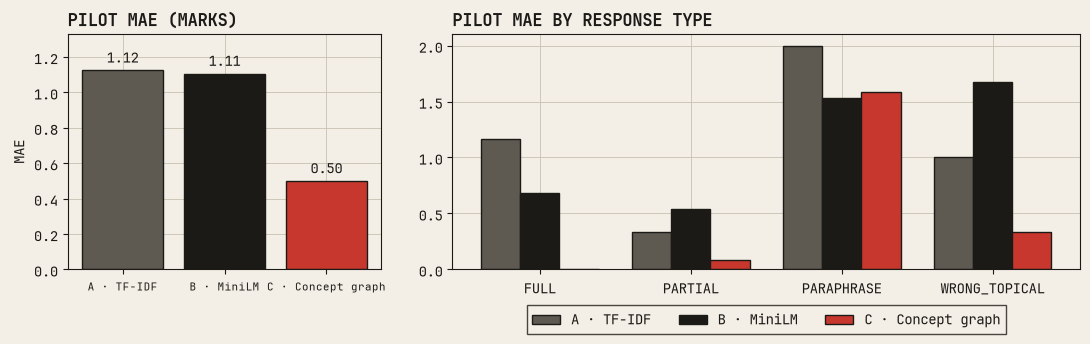

In [13]:
import matplotlib.pyplot as plt
from theme import PALETTE as P, MODEL_COLORS, mpl_style
mpl_style()
LBL = X.MODEL_LABELS; MAIN = ["A_tfidf", "B_embedding", "C_concept"]
pm = pd.read_csv(RESULTS / "pilot_metrics.csv").set_index("model")
bt = pd.read_csv(RESULTS / "pilot_by_type.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
vals = [pm.loc[m, "mae"] for m in MAIN]
ax.bar([LBL[m] for m in MAIN], vals, color=[MODEL_COLORS[m] for m in MAIN], edgecolor=P["ink"])
for i, v in enumerate(vals): ax.text(i, v + 0.02, f"{v:.2f}", ha="center", va="bottom")
ax.set_title("PILOT MAE (MARKS)"); ax.set_ylabel("MAE"); ax.tick_params(axis="x", labelsize=8); ax.set_ylim(0, max(vals) * 1.18)
ax = axes[1]
types = ["full", "partial", "paraphrase", "wrong_topical"]; w = 0.26
for j, m in enumerate(MAIN):
    s = bt[bt.model == m].set_index("response_type").reindex(types)
    ax.bar(np.arange(len(types)) + (j - 1) * w, s.mae, w, label=LBL[m], color=MODEL_COLORS[m], edgecolor=P["ink"])
ax.set_xticks(range(len(types)), [t.upper() for t in types]); ax.set_title("PILOT MAE BY RESPONSE TYPE")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.tight_layout(); fig.savefig(FIG / "pilot_mae.png", dpi=200); plt.show()

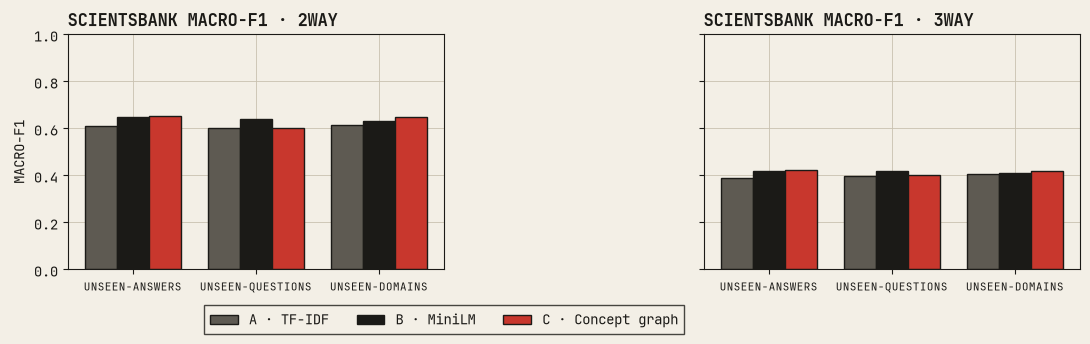

In [14]:
sm = pd.read_csv(RESULTS / "scientsbank_metrics.csv")
splits = ["unseen-answers", "unseen-questions", "unseen-domains"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, task in zip(axes, ["2way", "3way"]):
    for j, m in enumerate(MAIN):
        s = sm[(sm.task == task) & (sm.model == m)].set_index("split").reindex(splits)
        ax.bar(np.arange(3) + (j - 1) * 0.26, s.macro_f1, 0.26, label=LBL[m], color=MODEL_COLORS[m], edgecolor=P["ink"])
    ax.set_xticks(range(3), [s.upper() for s in splits], fontsize=8); ax.set_title(f"SCIENTSBANK MACRO-F1 · {task.upper()}")
axes[0].set_ylabel("MACRO-F1"); axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.12), ncol=3)
fig.tight_layout(); fig.savefig(FIG / "scientsbank_macro_f1.png", dpi=200); plt.show()

findfont: Failed to find font weight bold for JetBrains Mono, now using 558.


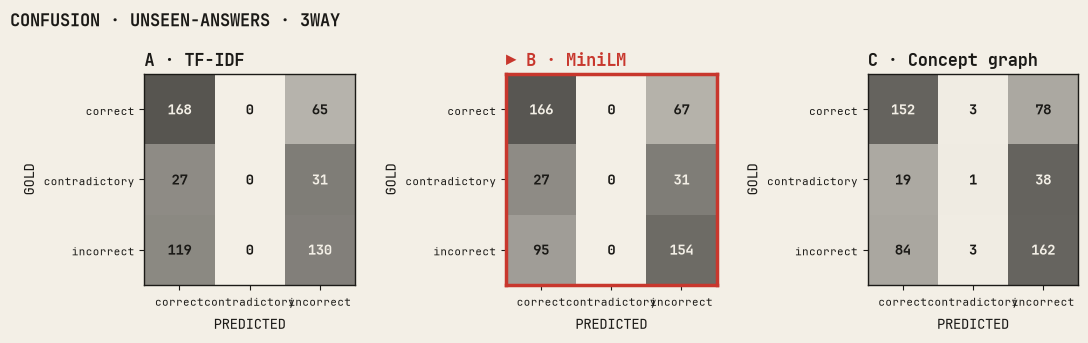

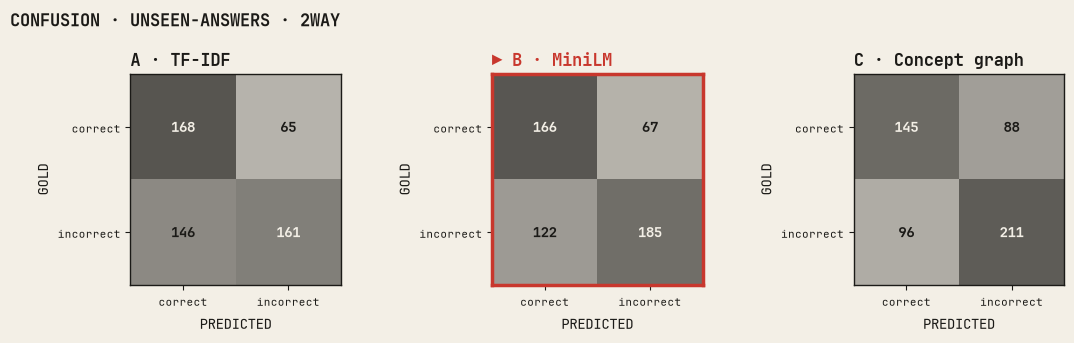

In [15]:
conf = pd.read_csv(RESULTS / "scientsbank_confusion.csv")
order = ["correct", "contradictory", "incorrect"]
for task in ["3way", "2way"]:
    labs = [l for l in order if l in set(conf[conf.task == task].gold)]
    best = sm[(sm.task == task) & sm.model.isin(MAIN) & (sm.split != "dev")].groupby("model").macro_f1.mean().idxmax()
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    for ax, m in zip(axes, MAIN):
        c = conf[(conf.task == task) & (conf.split == "unseen-answers") & (conf.model == m)].pivot(index="gold", columns="pred", values="count").reindex(index=labs, columns=labs)
        share = c.div(c.sum(axis=1).clip(lower=1), axis=0)
        ax.imshow(share.values, cmap="ledger", vmin=0, vmax=1); ax.grid(False)
        for i in range(len(labs)):
            for j in range(len(labs)):
                ax.text(j, i, int(c.values[i, j]), ha="center", va="center", fontweight="bold", color=P["paper"] if share.values[i, j] > 0.5 else P["ink"])
        ax.set_xticks(range(len(labs)), labs, fontsize=8); ax.set_yticks(range(len(labs)), labs, fontsize=8)
        ax.set_xlabel("PREDICTED"); ax.set_ylabel("GOLD")
        is_best = m == best
        ax.set_title(("▶ " if is_best else "") + LBL[m], color=P["redpen"] if is_best else P["ink"])
        for sp in ax.spines.values(): sp.set_edgecolor(P["redpen"] if is_best else P["ink"]); sp.set_linewidth(2.5 if is_best else 1)
    fig.suptitle(f"CONFUSION · UNSEEN-ANSWERS · {task.upper()}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); fig.savefig(FIG / f"confusion_unseen_answers_{task}.png", dpi=200); plt.show()

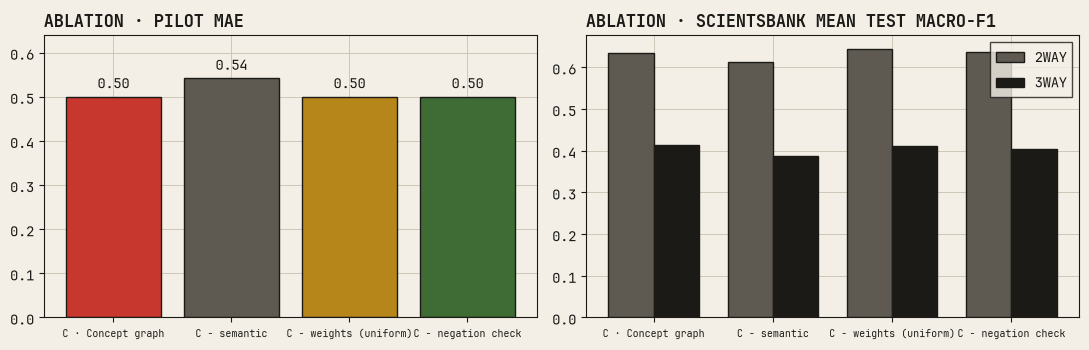

In [16]:
ap = pd.read_csv(RESULTS / "ablations_pilot.csv"); asb = pd.read_csv(RESULTS / "ablations_scientsbank.csv")
cols = [P["redpen"], P["ink-soft"], P["ochre"], P["moss"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar([LBL[m] for m in ap.model], ap.mae, color=cols, edgecolor=P["ink"])
for i, v in enumerate(ap.mae): axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom")
axes[0].set_title("ABLATION · PILOT MAE"); axes[0].tick_params(axis="x", labelsize=7); axes[0].set_ylim(0, ap.mae.max() * 1.18)
for j, task in enumerate(["2way", "3way"]):
    s = asb[asb.task == task].set_index("model").reindex(abl)
    axes[1].bar(np.arange(4) + (j - 0.5) * 0.38, s.macro_f1_test_mean, 0.38, label=task.upper(), color=[P["ink-soft"], P["ink"]][j], edgecolor=P["ink"])
axes[1].set_xticks(range(4), [LBL[m] for m in abl], fontsize=7); axes[1].set_title("ABLATION · SCIENTSBANK MEAN TEST MACRO-F1"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "ablations.png", dpi=200); plt.show()

## 6 · Metrics summary for the report (all values read from `results/`)

In [17]:
pm = pd.read_csv(RESULTS / "pilot_metrics.csv"); sm = pd.read_csv(RESULTS / "scientsbank_metrics.csv")
rows = []
for m in MAIN:
    p = pm.set_index("model").loc[m]
    row = {"model": LBL[m], "pilot_MAE": p.mae, "pilot_RMSE": p.rmse, "pilot_exact": p.exact_match}
    for task in ("2way", "3way"):
        for split in splits:
            r = sm[(sm.model == m) & (sm.task == task) & (sm.split == split)].iloc[0]
            row[f"{task}_{split}_acc"] = r.accuracy; row[f"{task}_{split}_mF1"] = r.macro_f1
    rows.append(row)
summary = pd.DataFrame(rows); summary.to_csv(RESULTS / "metrics_summary.csv", index=False)
print(summary.set_index("model").T.round(3).to_string())

model                      A · TF-IDF  B · MiniLM  C · Concept graph
pilot_MAE                       1.125       1.107              0.500
pilot_RMSE                      1.339       1.294              0.946
pilot_exact                     0.208       0.250              0.708
2way_unseen-answers_acc         0.609       0.650              0.659
2way_unseen-answers_mF1         0.609       0.650              0.654
2way_unseen-questions_acc       0.608       0.640              0.603
2way_unseen-questions_mF1       0.603       0.639              0.600
2way_unseen-domains_acc         0.618       0.631              0.650
2way_unseen-domains_mF1         0.616       0.630              0.650
3way_unseen-answers_acc         0.552       0.593              0.583
3way_unseen-answers_mF1         0.387       0.417              0.423
3way_unseen-questions_acc       0.578       0.604              0.559
3way_unseen-questions_mF1       0.397       0.419              0.400
3way_unseen-domains_acc         0.

In [18]:
print("files in results/:")
for p in sorted(RESULTS.rglob("*")):
    if p.is_file(): print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size:,} B)")

files in results/:
  results/ablations_pilot.csv  (728 B)
  results/ablations_scientsbank.csv  (1,202 B)
  results/environment.json  (407 B)
  results/figures/ablations.png  (67,145 B)
  results/figures/confusion_unseen_answers_2way.png  (64,931 B)
  results/figures/confusion_unseen_answers_3way.png  (86,968 B)
  results/figures/pilot_mae.png  (59,499 B)
  results/figures/scientsbank_macro_f1.png  (55,954 B)
  results/grader_configs.csv  (320 B)
  results/metrics_summary.csv  (1,183 B)
  results/pilot_by_type.csv  (1,651 B)
  results/pilot_metrics.csv  (708 B)
  results/pilot_predictions.csv  (52,494 B)
  results/pilot_sample_outputs.csv  (7,852 B)
  results/scientsbank_class_balance.csv  (963 B)
  results/scientsbank_confusion.csv  (16,925 B)
  results/scientsbank_metrics.csv  (5,713 B)
  results/scientsbank_predictions.csv  (6,191,791 B)
  results/scientsbank_scores.csv  (3,342,343 B)
  results/worst_errors_pilot.csv  (5,163 B)
  results/worst_errors_scientsbank.csv  (7,005 B)
